# Evaluación Parcial 2: Machine Learning supervisado

**Asignatura:** MLY0100 | **Estudiante:** Nicolás Vega | **Fecha:** 5 de noviembre de 2026

**Dataset:** Properati limpio de EV1. **CRISP-DM:** fases 4 (Modelado) y 5 (Evaluación).

En este trabajo desarrollé dos tareas: regresión para estimar price en USD y clasificación de property_type en Departamento, Casa, PH y Otros. Las conclusiones se generan a partir de las métricas ejecutadas.

## 1. Contexto y objetivos

El caso estudia publicaciones de propiedades en venta de Argentina, usando el dataset Properati preparado en la Evaluación Parcial 1.

Se desarrollan dos tareas distintas:

- **Regresión:** el target es price, un valor numérico continuo expresado en USD. El modelo debe estimar un precio.
- **Clasificación:** el target es clase, una variable categórica con cuatro valores: Departamento, Casa, PH y Otros. El modelo debe decidir a qué categoría pertenece cada publicación.

En regresión se evalúa qué tan cerca queda el precio estimado del precio real, por eso se usan MAE, RMSE y R². En clasificación se evalúa si la categoría predicha coincide con la real, por eso se usan accuracy, precision, recall, F1 y ROC-AUC.

Los modelos de regresión y clasificación no son intercambiables: por ejemplo, se utiliza KNeighborsRegressor para estimar un monto y KNeighborsClassifier para asignar una categoría. property_type se usa como característica para estimar price, pero se excluye de los atributos de clasificación porque es el target. title y description no se usan para clasificar, ya que pueden mencionar directamente el tipo de propiedad y producir fuga de información.

## 2. Librerías

Se utilizan Pandas, NumPy, Matplotlib, Seaborn, Scikit-Learn e imbalanced-learn para preparar, modelar y evaluar los datos.

In [1]:
# Importamos las librerías que utilizaremos
import os
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix
)
from imblearn.over_sampling import RandomOverSampler

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
pd.set_option('display.max_columns', 40)

print('Librerías cargadas correctamente.')

Librerías cargadas correctamente.


### Mi explicación de los resultados

**Por qué lo hice así:** Primero importé las librerías que necesito para leer los datos, hacer los gráficos y entrenar los modelos. Usé Pandas para manejar tablas, NumPy para los cálculos, Matplotlib y Seaborn para visualizar, y Scikit-Learn para los modelos y sus métricas. También incorporé imbalanced-learn porque después compararé clases balanceadas y desbalanceadas.

**Qué resultado obtuve:** La celda imprimió **«Librerías cargadas correctamente»**, por lo que las importaciones se ejecutaron sin errores en la ejecución guardada. Todavía no hay una predicción ni un gráfico para interpretar.

**Qué concluyo:** Este paso no demuestra que un modelo sea bueno; simplemente deja preparado el entorno. Definí además una semilla fija para poder repetir las divisiones y comparar resultados de forma consistente.


## 3. Carga del dataset limpio de EV1

Se busca el CSV preparado. Si no existe, se reconstruye desde el ZIP aplicando la limpieza final de EV1: medianas agrupadas e identificación conjunta de outliers mediante IQR y Z-score. Se conservan variables originales; los escaladores se ajustan nuevamente después de la división train/test para evitar fuga de información.

In [2]:
COLUMNAS_MODELO = [
    'lat', 'lon', 'l2', 'l3', 'rooms', 'bedrooms', 'bathrooms',
    'surface_total', 'surface_covered', 'price', 'property_type'
]
COLUMNAS_NUMERICAS_EV1 = [
    'rooms', 'bedrooms', 'bathrooms', 'surface_total',
    'surface_covered', 'price', 'lat', 'lon'
]


def localizar_archivo(nombre):
    candidatos = [
        Path.cwd() / nombre,
        Path.cwd().parent / nombre,
        Path('/content') / nombre,
        Path('/content/drive/MyDrive') / nombre
    ]
    for ruta in candidatos:
        if ruta.exists():
            return ruta
    return None


ruta_preparado = localizar_archivo('DS1-18-Datos-Properati-preparado.csv')
ruta_zip = localizar_archivo('Evaluación Parcial 1 - Dataset.zip')

if ruta_preparado is not None:
    print(f'Leyendo dataset preparado de EV1: {ruta_preparado}')
    df = pd.read_csv(ruta_preparado, usecols=lambda c: c in COLUMNAS_MODELO, low_memory=False)
else:
    if ruta_zip is None:
        raise FileNotFoundError(
            'No se encontró el CSV preparado ni el ZIP original. '
            'Coloca "Evaluación Parcial 1 - Dataset.zip" en la raíz del repositorio '
            'o ejecuta primero notebook/evaluacion_parcial_1.ipynb.'
        )
    print(f'No existe el CSV preparado. Se reconstruye la limpieza final de EV1 desde: {ruta_zip}')
    with zipfile.ZipFile(ruta_zip) as archivo_zip:
        nombre_csv = next(n for n in archivo_zip.namelist() if n.endswith('DS1-18-Datos-Properati.csv'))
        with archivo_zip.open(nombre_csv) as archivo_csv:
            df = pd.read_csv(archivo_csv, usecols=COLUMNAS_MODELO, low_memory=False)

    # Imputación final utilizada en EV1: medianas por tipo de propiedad y localidad.
    for columna in ['surface_total', 'surface_covered', 'bathrooms']:
        mediana_grupo = df.groupby('property_type', observed=False)[columna].transform('median')
        df[columna] = df[columna].fillna(mediana_grupo)

    for columna in ['lat', 'lon']:
        mediana_grupo = df.groupby('l3', observed=False)[columna].transform('median')
        df[columna] = df[columna].fillna(mediana_grupo)

    # Criterio de EV1: eliminar solo los registros marcados por IQR y Z-score a la vez.
    mascara_extremos = np.zeros(len(df), dtype=bool)
    for columna in COLUMNAS_NUMERICAS_EV1:
        q1 = df[columna].quantile(0.25)
        q3 = df[columna].quantile(0.75)
        iqr = q3 - q1
        mascara_iqr = ((df[columna] < q1 - 1.5 * iqr) | (df[columna] > q3 + 1.5 * iqr)).to_numpy()
        z_score = np.abs(stats.zscore(df[columna].to_numpy(), nan_policy='omit'))
        mascara_z = z_score > 3
        mascara_extremos |= mascara_iqr & mascara_z
    df = df.loc[~mascara_extremos].copy()

# Tipos consistentes para el análisis y el preprocesamiento.
for columna in ['l2', 'l3', 'property_type']:
    df[columna] = df[columna].astype('string').fillna('Sin dato').astype(str)

for columna in ['lat', 'lon', 'rooms', 'bedrooms', 'bathrooms', 'surface_total', 'surface_covered', 'price']:
    df[columna] = pd.to_numeric(df[columna], errors='coerce')

df = df.dropna(subset=COLUMNAS_MODELO).copy()
df = df.replace([np.inf, -np.inf], np.nan).dropna(subset=COLUMNAS_MODELO).copy()

print('Dimensiones del dataset utilizado:', df.shape)
print('Valores faltantes en columnas de modelado:', int(df[COLUMNAS_MODELO].isna().sum().sum()))
print('Tipos de propiedad originales:')
display(df['property_type'].value_counts().to_frame('cantidad'))

No existe el CSV preparado. Se reconstruye la limpieza final de EV1 desde: /home/runner/work/Machine-learning-1/Machine-learning-1/Evaluación Parcial 1 - Dataset.zip


Dimensiones del dataset utilizado: (141934, 11)
Valores faltantes en columnas de modelado: 0
Tipos de propiedad originales:


,cantidad
property_type,
Departamento,104778
Casa,20008
PH,14011
Lote,1172
Oficina,643
Local comercial,301
Otro,284
Casa de campo,275
Cochera,259


### Mi explicación de los resultados

**Por qué lo hice así:** Antes de entrenar cualquier modelo necesitaba trabajar con datos utilizables. Busqué el archivo limpio de la Evaluación 1 y, como no estaba disponible en esa ejecución, el código reconstruyó la preparación desde el ZIP original. Revisé valores faltantes, tipos de datos y registros extremos según los criterios definidos anteriormente.

**Qué resultados muestran las tablas:** Quedaron **141.934 registros y 11 columnas**, con **0 valores faltantes** en las columnas utilizadas para modelar. La tabla muestra que predominan los **104.778 departamentos**, frente a **20.008 casas** y **14.011 PH**, mientras que otros tipos aparecen mucho menos.

**Qué concluyo:** Ya cuento con un conjunto que puedo usar para modelar. También descubrí desde el principio que los tipos de propiedad no tienen la misma cantidad de registros, algo que después debo considerar al evaluar la clasificación. Tener muchas filas no significa que todas las categorías estén igualmente representadas.


## 4. Targets y distribución

price se utiliza como target continuo y se mantiene en su escala original de dólares para que las predicciones y los errores se puedan interpretar directamente en USD. Su distribución es asimétrica, por eso se muestra también el histograma de log1p(price), pero en esta evaluación no se transforma el target.

Para clasificación se agrupan las publicaciones en cuatro clases: Departamento, Casa, PH y Otros. En Otros se incluyen Lote, Oficina, Local comercial, Casa de campo, Depósito, Cochera y Otro.

Target de regresión:
dtype: float64
Cantidad de valores únicos: 6506
count    1.419340e+05
mean     2.092873e+05
std      1.555714e+05
min      5.500000e+03
25%      1.100000e+05
50%      1.630000e+05
75%      2.549750e+05
max      1.195000e+06
Name: price, dtype: float64

Target de clasificación:
dtype: str
Cantidad de clases: 4


,cantidad
clase,
Departamento,104778
Casa,20008
PH,14011
Otros,3137


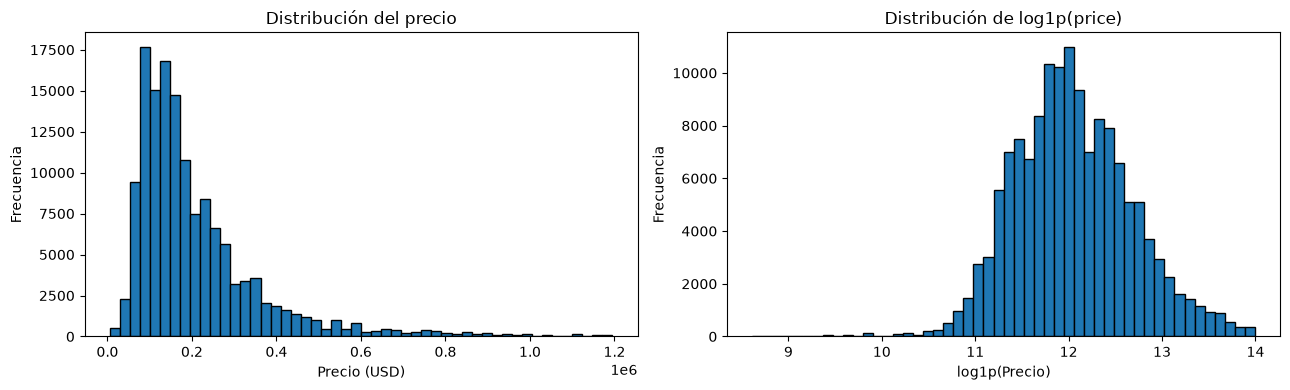

,cantidad,porcentaje
clase,,
Departamento,104778,73.82
Casa,20008,14.10
PH,14011,9.87
Otros,3137,2.21


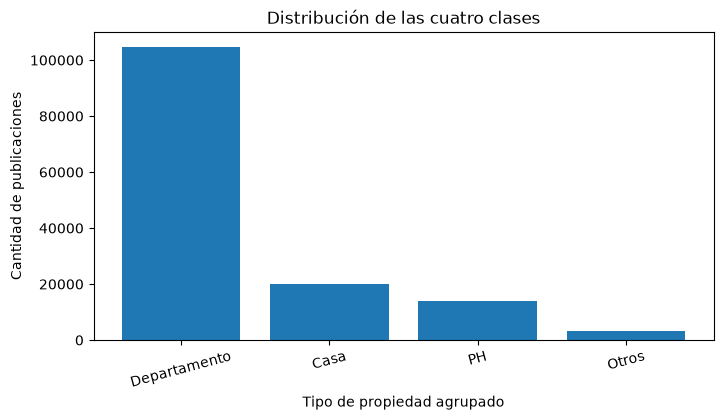

In [3]:
df['clase'] = np.where(
    df['property_type'].isin(['Departamento', 'Casa', 'PH']),
    df['property_type'],
    'Otros'
)

print('Target de regresión:')
print('dtype:', df['price'].dtype)
print('Cantidad de valores únicos:', df['price'].nunique())
print(df['price'].describe())

print('\nTarget de clasificación:')
print('dtype:', df['clase'].dtype)
print('Cantidad de clases:', df['clase'].nunique())
display(df['clase'].value_counts().to_frame('cantidad'))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(df['price'], bins=50, edgecolor='black')
ax[0].set_title('Distribución del precio')
ax[0].set_xlabel('Precio (USD)')
ax[0].set_ylabel('Frecuencia')
ax[1].hist(np.log1p(df['price']), bins=50, edgecolor='black')
ax[1].set_title('Distribución de log1p(price)')
ax[1].set_xlabel('log1p(Precio)')
ax[1].set_ylabel('Frecuencia')
plt.tight_layout()
plt.show()

frecuencias = df['clase'].value_counts()
porcentajes = (df['clase'].value_counts(normalize=True) * 100).round(2)
display(pd.DataFrame({'cantidad': frecuencias, 'porcentaje': porcentajes}))

plt.figure(figsize=(8, 4))
plt.bar(frecuencias.index.astype(str), frecuencias.values)
plt.title('Distribución de las cuatro clases')
plt.xlabel('Tipo de propiedad agrupado')
plt.ylabel('Cantidad de publicaciones')
plt.xticks(rotation=15)
plt.show()

### Mi explicación de los resultados y los gráficos

**Por qué lo hice así:** Quise identificar claramente las dos variables que voy a predecir. Para regresión utilicé `price`, que es numérica y se expresa en dólares. Para clasificación reuní los tipos de propiedad en cuatro grupos: Departamento, Casa, PH y Otros. Después dibujé histogramas y un gráfico de barras para conocer su distribución.

**Qué muestran los histogramas de precios:** El precio medio es de aproximadamente **USD 209.287**, pero la mediana es **USD 163.000**. Eso significa que hay propiedades de precio elevado que empujan el promedio hacia arriba. Los valores van desde **USD 5.500** hasta **USD 1.195.000**. En el histograma original los precios se concentran más en los valores bajos y medios, con una cola hacia los precios altos. El histograma de `log1p(price)` comprime los valores grandes y permite apreciar mejor cómo se distribuyen; **solo se usa para visualizar**, no para cambiar la variable que se predice.

**Qué muestra el gráfico de barras:** **Departamento representa el 73,82 %**, Casa el **14,10 %**, PH el **9,87 %** y Otros apenas el **2,21 %**. La barra de Departamento es mucho más alta que las demás.

**Qué concluyo:** El precio tiene una distribución asimétrica y las clases están desbalanceadas. Por eso evaluaré los errores monetarios en regresión y, en clasificación, no me quedaré solo con el porcentaje global de aciertos.


## 5. División train/test

Se utilizan muestras reproducibles de hasta 12.000 registros para regresión y 8.000 para clasificación. La muestra de clasificación y su división 80/20 son estratificadas. Los cuatro modelos usan la misma división.

In [4]:
# REGRESIÓN: muestra aleatoria reproducible y división 80/20.
N_REGRESION = min(12_000, len(df))
df_reg = df.sample(n=N_REGRESION, random_state=RANDOM_STATE).copy()

features_reg_numericas = ['rooms', 'bathrooms', 'surface_total', 'surface_covered', 'lat', 'lon']
features_reg_categoricas = ['l2', 'l3', 'property_type']
features_reg = features_reg_numericas + features_reg_categoricas
X_reg = df_reg[features_reg].copy()
y_reg = df_reg['price'].astype(float).copy()

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=RANDOM_STATE
)

# CLASIFICACIÓN: muestra estratificada de hasta 8.000 registros.
N_CLASIFICACION = min(8_000, len(df))
df_clf, _ = train_test_split(
    df, train_size=N_CLASIFICACION, stratify=df['clase'], random_state=RANDOM_STATE
)

features_clf_numericas = ['rooms', 'bathrooms', 'surface_total', 'surface_covered', 'lat', 'lon']
features_clf_categoricas = ['l2', 'l3']
features_clf = features_clf_numericas + features_clf_categoricas
X_clf = df_clf[features_clf].copy()
y_clf = df_clf['clase'].copy()

X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=0.20, random_state=RANDOM_STATE, stratify=y_clf
)

print('Regresión | train:', X_train_reg.shape, '| test:', X_test_reg.shape)
print('Clasificación | train:', X_train_clf.shape, '| test:', X_test_clf.shape)
print('\nDistribución de clasificación en entrenamiento:')
display(y_train_clf.value_counts().to_frame('cantidad_train'))
print('Distribución de clasificación en prueba:')
display(y_test_clf.value_counts().to_frame('cantidad_test'))

Regresión | train: (9600, 9) | test: (2400, 9)
Clasificación | train: (6400, 8) | test: (1600, 8)

Distribución de clasificación en entrenamiento:


,cantidad_train
clase,
Departamento,4725
Casa,902
PH,631
Otros,142


Distribución de clasificación en prueba:


,cantidad_test
clase,
Departamento,1181
Casa,226
PH,158
Otros,35


### Mi explicación de los resultados

**Por qué lo hice así:** Separé una parte de los datos para aprender y otra para comprobar qué tan bien predicen los modelos sin haber visto esas observaciones. Utilicé la proporción **80 % entrenamiento y 20 % prueba**. En clasificación, además, apliqué una división **estratificada**, porque las cuatro categorías tienen cantidades muy diferentes.

**Qué muestran las tablas:** Para regresión quedaron **9.600 filas de entrenamiento y 2.400 de prueba**, cada una con 9 características originales. Para clasificación quedaron **6.400 de entrenamiento y 1.600 de prueba**, con 8 características. En el entrenamiento de clasificación hay **4.725 departamentos, 902 casas, 631 PH y 142 Otros**; en prueba aparecen **1.181, 226, 158 y 35**, respectivamente. Las proporciones se mantienen muy similares.

**Qué concluyo:** La división es coherente con el objetivo: entrenar por separado y medir después el comportamiento con datos nuevos. La estratificación evita que una clase minoritaria desaparezca por casualidad de alguno de los conjuntos.


## 6. Correlación

La correlación se analiza en entrenamiento. Pearson resume relaciones lineales y Spearman relaciones monótonas. Se revisan pares con |r| > 0,8 y la relación de los atributos numéricos con el precio.

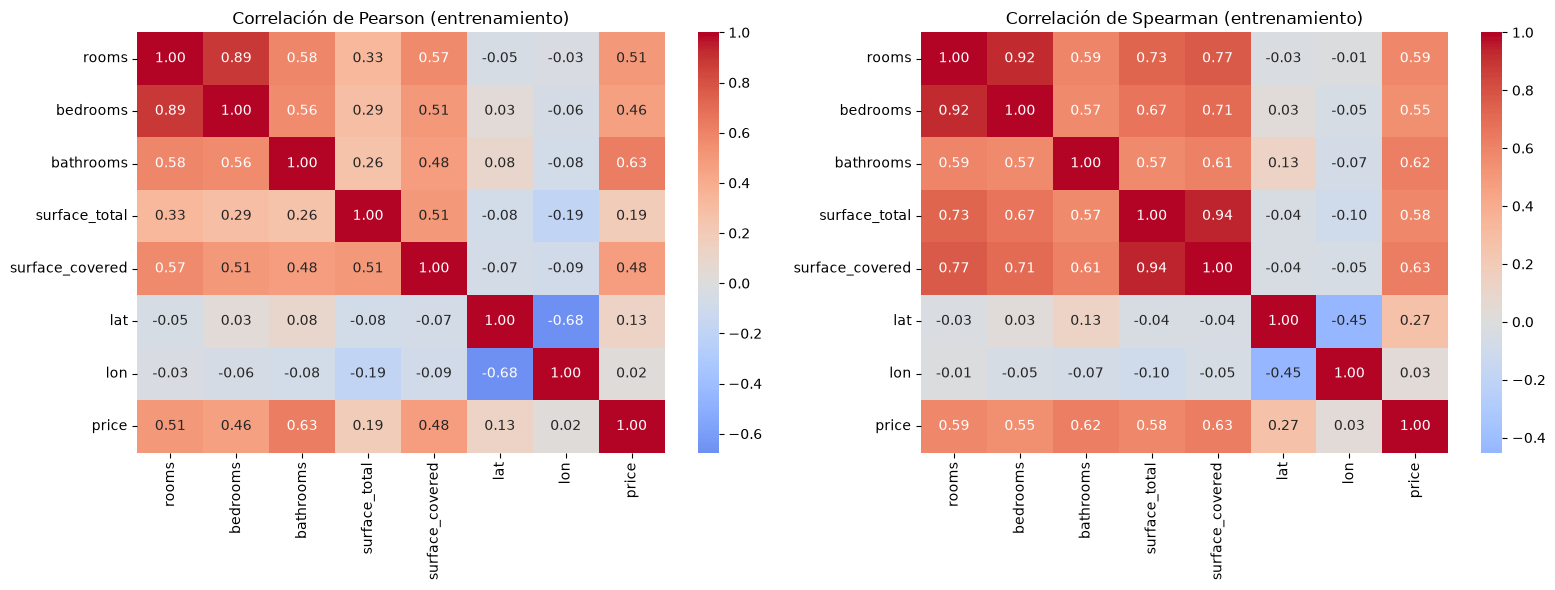

Correlación entre rooms y bedrooms en el conjunto de entrenamiento:
Pearson: 0.887
Spearman: 0.921
Correlación de Spearman de cada variable numérica con price:


,spearman_con_price
surface_covered,0.627375
bathrooms,0.620150
rooms,0.585961
surface_total,0.581134
bedrooms,0.550906
lat,0.269522
lon,0.034330


,feature_1,feature_2,pearson
0,rooms,bedrooms,0.886784


,rooms,bathrooms,surface_total,surface_covered,lat,lon,bedrooms
clase,,,,,,,
Casa,4.0,2.0,300.0,160.0,-34.64,-58.52,3.0
Departamento,3.0,1.0,67.0,60.0,-34.60,-58.44,2.0
Otros,1.0,1.0,432.5,144.0,-34.64,-58.45,1.0
PH,3.0,1.0,106.0,80.0,-34.61,-58.46,2.0


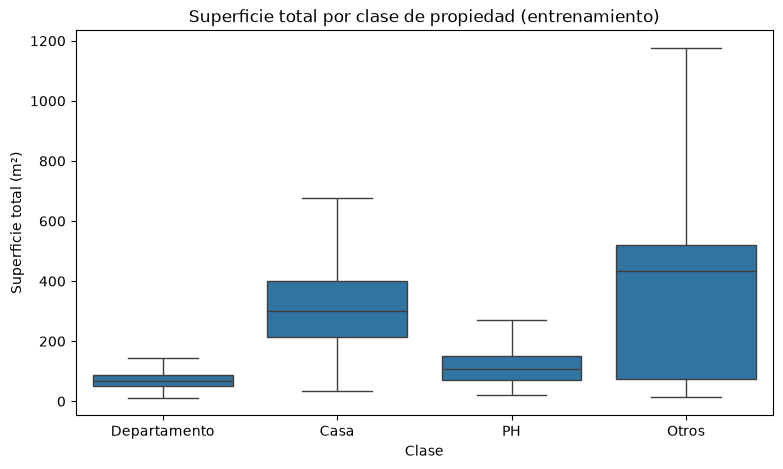

In [5]:
# bedrooms se incorpora al análisis exploratorio para justificar su descarte,
# pero no se entrega a los modelos porque presenta alta correlación con rooms.
features_corr_numericas = [
    'rooms', 'bedrooms', 'bathrooms', 'surface_total',
    'surface_covered', 'lat', 'lon'
]
df_corr_train = df_reg.loc[X_train_reg.index, features_corr_numericas].copy()
df_corr_train['price'] = y_train_reg

corr_pearson = df_corr_train.corr(method='pearson')
corr_spearman = df_corr_train.corr(method='spearman')

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(corr_pearson, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax[0])
ax[0].set_title('Correlación de Pearson (entrenamiento)')
sns.heatmap(corr_spearman, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax[1])
ax[1].set_title('Correlación de Spearman (entrenamiento)')
plt.tight_layout()
plt.show()

print('Correlación entre rooms y bedrooms en el conjunto de entrenamiento:')
print(f"Pearson: {corr_pearson.loc['rooms', 'bedrooms']:.3f}")
print(f"Spearman: {corr_spearman.loc['rooms', 'bedrooms']:.3f}")

correlacion_precio = corr_spearman['price'].drop('price').sort_values(key=np.abs, ascending=False)
print('Correlación de Spearman de cada variable numérica con price:')
display(correlacion_precio.to_frame('spearman_con_price'))

pares_fuertes = []
for i, variable_a in enumerate(features_corr_numericas):
    for variable_b in features_corr_numericas[i + 1:]:
        valor = corr_pearson.loc[variable_a, variable_b]
        if abs(valor) > 0.8:
            pares_fuertes.append((variable_a, variable_b, valor))

if pares_fuertes:
    display(pd.DataFrame(pares_fuertes, columns=['feature_1', 'feature_2', 'pearson']).sort_values('pearson'))
else:
    print('No se encontraron pares con |Pearson| > 0,8 entre las variables analizadas.')

# Para clasificación también se revisan las medianas por clase, incluyendo
# bedrooms como variable de diagnóstico, aunque no se usa para entrenar.
df_clf_train_eda = X_train_clf.copy()
df_clf_train_eda['bedrooms'] = df_clf.loc[X_train_clf.index, 'bedrooms']
df_clf_train_eda['clase'] = y_train_clf
features_clf_eda = features_clf_numericas + ['bedrooms']
medianas_por_clase = df_clf_train_eda.groupby('clase')[features_clf_eda].median().round(2)
display(medianas_por_clase)

plt.figure(figsize=(9, 5))
sns.boxplot(data=df_clf_train_eda, x='clase', y='surface_total', showfliers=False)
plt.title('Superficie total por clase de propiedad (entrenamiento)')
plt.xlabel('Clase')
plt.ylabel('Superficie total (m²)')
plt.show()

### Mi explicación de los resultados y los gráficos

**Por qué lo hice así:** Calculé las correlaciones de **Pearson y Spearman** para identificar variables parecidas y otras que podrían ayudar a estimar el precio. Usé mapas de calor para comparar todas las relaciones de manera visual y un gráfico de cajas para ver cómo cambia la superficie entre categorías.

**Qué muestran los mapas de calor:** La relación entre `rooms` y `bedrooms` es alta: **Pearson = 0,887** y **Spearman = 0,921**. Ambas variables se mueven de manera muy parecida, por lo que decidí conservar `rooms` y descartar `bedrooms` en los modelos. Respecto del precio, las correlaciones de Spearman más altas entre las variables mostradas son **surface_covered (0,627)**, **bathrooms (0,620)**, **rooms (0,586)** y **surface_total (0,581)**. En cambio, `lon` tiene una relación monotónica muy débil con el precio (**0,034**). Estas relaciones no prueban causalidad.

**Qué muestra el gráfico de cajas de superficie:** Las superficies típicas son distintas por categoría. La mediana de `surface_total` es **300 m² en Casa**, **67 m² en Departamento**, **106 m² en PH** y **432,5 m² en Otros**. Las cajas permiten comparar la variación de los datos dentro de cada grupo; los valores atípicos se ocultaron en esta visualización para que fuera más legible.

**Qué concluyo:** Las características de tamaño y cantidad de ambientes contienen información útil, pero hay variables redundantes. También veo por qué el tamaño de la propiedad puede ayudar a clasificar su tipo, aunque por sí solo no garantice una clasificación correcta.


### Decisiones de selección de features

- Se conserva **rooms** y se descarta **bedrooms** en regresión y clasificación para reducir multicolinealidad. En el conjunto de entrenamiento, Pearson entre ambas es aproximadamente **0,887** y Spearman **0,921**. Son asociaciones altas y describen dimensiones cercanas del tamaño de la vivienda.
- Se conservan **surface_total** y **surface_covered**: describen superficie total y cubierta. En la matriz de entrenamiento no superan entre sí el umbral de referencia |r| > 0,8, por lo que aportan información complementaria.
- Se conservan **bathrooms**, **lat** y **lon** por su relación con características físicas y ubicación. Pearson y Spearman permiten observar relaciones lineales y monótonas con price.
- **l2** y **l3** se codifican con One-Hot Encoding. Son variables nominales, por lo que no corresponde asignarles un orden numérico artificial.
- Para regresión se incluye **property_type**, porque el tipo de inmueble es conocido al estimar su precio. Para clasificación se excluye porque es la variable objetivo.
- Se descartan **title** y **description** para clasificación por riesgo de data leakage; también se descartan fechas sin transformar, columnas constantes (l1, currency, operation_type) y columnas escaladas en EV1, que se ajustaron antes de separar train/test.
- **price_minmax** se excluye siempre de los features porque es una transformación directa del target price.

Estas decisiones reducen redundancia y evitan entregar al modelo información que no estaría disponible de forma legítima al realizar una predicción.

## 7. Preparación de los datos para regresión

Primero separamos las variables categóricas y las convertimos a números usando One-Hot Encoding. Después normalizamos los datos con StandardScaler. El escalador se ajusta con los datos de entrenamiento y luego se aplica a los datos de prueba.

In [6]:
# Aplicamos One-Hot Encoding a las variables categóricas
X_train_reg_dummies = pd.get_dummies(
    X_train_reg,
    columns=features_reg_categoricas,
    drop_first=True
)

X_test_reg_dummies = pd.get_dummies(
    X_test_reg,
    columns=features_reg_categoricas,
    drop_first=True
)

# Dejamos las mismas columnas en entrenamiento y prueba
X_test_reg_dummies = X_test_reg_dummies.reindex(
    columns=X_train_reg_dummies.columns,
    fill_value=0
)

print('Dimensión de X_train:', X_train_reg_dummies.shape)
print('Dimensión de X_test:', X_test_reg_dummies.shape)

# Normalizamos los datos
scaler_reg = StandardScaler()

X_train_reg_scaled = scaler_reg.fit_transform(X_train_reg_dummies)
X_test_reg_scaled = scaler_reg.transform(X_test_reg_dummies)

print('Datos de regresión preparados correctamente.')

Dimensión de X_train: (9600, 105)
Dimensión de X_test: (2400, 105)
Datos de regresión preparados correctamente.


### Mi explicación de los resultados

**Por qué lo hice así:** Algunos modelos no pueden trabajar directamente con palabras como localidad o tipo de propiedad. Por eso convertí esas categorías a columnas numéricas mediante **One-Hot Encoding** y normalicé los valores con **StandardScaler**. Ajusté el escalador solo con entrenamiento para no adelantar información de prueba.

**Qué muestra la salida:** Después de la transformación, pasé de las **9 características originales** a **105 columnas numéricas** para regresión. Tanto entrenamiento como prueba tienen esas mismas 105 columnas; sus dimensiones son **(9.600, 105)** y **(2.400, 105)**.

**Qué concluyo:** Las nuevas columnas no representan 105 variables originales distintas: muchas son indicadores de categorías. Al mantener el mismo orden de columnas y la escala comparable, puedo entrenar y evaluar sin errores por diferencias entre los conjuntos. Esto es especialmente importante para KNN, que compara distancias entre propiedades.


## 8. Modelos de regresión

Implementaremos dos modelos vistos en la asignatura:

- **Regresión lineal múltiple:** sirve como modelo base. Estima el precio a partir de la combinación de varias características de la propiedad.
- **KNN Regressor:** estima el precio mirando propiedades con características similares. Se incluye porque puede representar relaciones que no sean estrictamente lineales. Como trabaja con distancias, necesita que los atributos estén normalizados.

La variable que queremos predecir es price, expresada en dólares. Ambos modelos se entrenan con la misma división de datos para comparar sus resultados de manera justa.

In [7]:
# Creamos el modelo de Regresión Lineal
modelo_lineal = LinearRegression()

# Entrenamos el modelo
modelo_lineal.fit(X_train_reg_scaled, y_train_reg)

# Realizamos las predicciones
pred_lineal_train = modelo_lineal.predict(X_train_reg_scaled)
pred_lineal_test = modelo_lineal.predict(X_test_reg_scaled)

# Creamos el modelo KNN
modelo_knn_reg = KNeighborsRegressor(n_neighbors=7)

# Entrenamos el modelo
modelo_knn_reg.fit(X_train_reg_scaled, y_train_reg)

# Realizamos las predicciones
pred_knn_train = modelo_knn_reg.predict(X_train_reg_scaled)
pred_knn_test = modelo_knn_reg.predict(X_test_reg_scaled)

print('Modelos de regresión entrenados correctamente.')

Modelos de regresión entrenados correctamente.


### Mi explicación de los resultados

**Por qué lo hice así:** Entrené **Regresión Lineal** y **KNN Regressor** con los mismos datos para comparar dos formas de estimar precios. La primera obtiene una combinación lineal de las características; KNN se apoya en propiedades similares.

**Qué muestra la salida:** El mensaje **«Modelos de regresión entrenados correctamente»** confirma que ambos modelos se ajustaron sin errores en la ejecución guardada. También se generaron predicciones de entrenamiento y prueba, pero esta celda todavía no muestra cuánto se equivocaron.

**Qué concluyo:** Haber entrenado un modelo no basta para elegirlo. Necesito comparar las predicciones con los precios reales mediante MAE, RMSE y R², que calculo en la siguiente actividad.


## 9. Evaluación de los modelos de regresión

Utilizaremos tres métricas, calculadas tanto en entrenamiento como en prueba:

- **MAE:** error absoluto promedio. Se interpreta directamente en dólares y permite decir cuánto se equivoca el modelo, en promedio, al estimar el precio.
- **RMSE:** también se expresa en dólares, pero penaliza más los errores grandes. Es útil porque una estimación muy alejada del precio real puede ser especialmente problemática.
- **R²:** indica qué proporción de la variación del precio logra explicar el modelo. Cuanto más se acerca a 1, mejor es el ajuste; puede ser negativo si el modelo funciona muy mal.

La decisión no se toma mirando solo el entrenamiento. Lo importante es el resultado en propiedades que el modelo no utilizó para aprender.

In [8]:
# Calculamos las métricas de Regresión Lineal
mae_lineal_train = mean_absolute_error(y_train_reg, pred_lineal_train)
mae_lineal_test = mean_absolute_error(y_test_reg, pred_lineal_test)

rmse_lineal_train = np.sqrt(mean_squared_error(y_train_reg, pred_lineal_train))
rmse_lineal_test = np.sqrt(mean_squared_error(y_test_reg, pred_lineal_test))

r2_lineal_train = r2_score(y_train_reg, pred_lineal_train)
r2_lineal_test = r2_score(y_test_reg, pred_lineal_test)

# Calculamos las métricas de KNN
mae_knn_train = mean_absolute_error(y_train_reg, pred_knn_train)
mae_knn_test = mean_absolute_error(y_test_reg, pred_knn_test)

rmse_knn_train = np.sqrt(mean_squared_error(y_train_reg, pred_knn_train))
rmse_knn_test = np.sqrt(mean_squared_error(y_test_reg, pred_knn_test))

r2_knn_train = r2_score(y_train_reg, pred_knn_train)
r2_knn_test = r2_score(y_test_reg, pred_knn_test)

# Creamos una tabla para comparar los resultados
tabla_regresion = pd.DataFrame({
    'MAE_train': [mae_lineal_train, mae_knn_train],
    'MAE_test': [mae_lineal_test, mae_knn_test],
    'RMSE_train': [rmse_lineal_train, rmse_knn_train],
    'RMSE_test': [rmse_lineal_test, rmse_knn_test],
    'R2_train': [r2_lineal_train, r2_knn_train],
    'R2_test': [r2_lineal_test, r2_knn_test]
}, index=['Regresión Lineal', 'KNN Regressor'])

display(tabla_regresion.round(3))

,MAE_train,MAE_test,RMSE_train,RMSE_test,R2_train,R2_test
Regresión Lineal,58731.962,58400.066,92444.129,91898.064,0.635,0.659
KNN Regressor,43546.665,48611.804,73790.417,81022.743,0.767,0.735


### Mi explicación de los resultados

**Por qué lo hice así:** Calculé las mismas métricas para ambos regresores y tanto en entrenamiento como en prueba. Utilicé **MAE** para medir el error promedio en dólares, **RMSE** para dar más peso a los errores grandes y **R²** para ver cuánta variación del precio logra explicar cada modelo.

**Qué muestra la tabla:** La **Regresión Lineal** obtuvo **MAE de prueba = USD 58.400,07**, **RMSE = USD 91.898,06** y **R² = 0,659**. **KNN Regressor** obtuvo **MAE = USD 48.611,80**, **RMSE = USD 81.022,74** y **R² = 0,735**. Para KNN, el MAE en entrenamiento fue **USD 43.546,67**; para la Regresión Lineal fue **USD 58.731,96**.

**Qué concluyo:** KNN se equivoca menos al estimar precios de propiedades que no utilizó para entrenar. La mejora no significa que sus predicciones sean exactas: equivocarse en unos USD 48.612, en promedio absoluto, sigue siendo importante para una decisión inmobiliaria. Por eso lo trataría como una referencia, no como una tasación definitiva.


### Selección del mejor modelo de regresión

Se compara el MAE de prueba y también la diferencia entre entrenamiento y prueba. En esta ejecución, KNN obtuvo un MAE de prueba de **USD 48.611,80**, frente a **USD 58.400,07** de la regresión lineal. Además, el RMSE de KNN fue **USD 81.022,74**, frente a **USD 91.898,06**, y su R² de prueba fue **0,735**, frente a **0,659**.

KNN presenta una diferencia de MAE entre entrenamiento y prueba de aproximadamente **USD 5.065,14**. La regresión lineal tiene una diferencia menor, de aproximadamente **USD 331,90**, pero su error de prueba es mayor. Para este caso se selecciona KNN porque estima los precios con menor error en datos no vistos y explica una mayor proporción de su variación. La diferencia entre entrenamiento y prueba se revisa para comprobar que esa mejora no se deba solamente a memorizar los datos.

,MAE_train,MAE_test,RMSE_train,RMSE_test,R2_train,R2_test,Diferencia_MAE
Regresión Lineal,58731.962,58400.066,92444.129,91898.064,0.635,0.659,331.895
KNN Regressor,43546.665,48611.804,73790.417,81022.743,0.767,0.735,5065.139


El modelo con menor error en prueba es: KNN Regressor
MAE de prueba: USD 48611.8
RMSE de prueba: USD 81022.74
R2 de prueba: 0.735

Diagnóstico de los modelos de regresión:
Regresión Lineal
R2 entrenamiento: 0.635
R2 prueba: 0.659
Diferencia: -0.024
No se observa una brecha importante entre entrenamiento y prueba.
---
KNN Regressor
R2 entrenamiento: 0.767
R2 prueba: 0.735
Diferencia: 0.032
No se observa una brecha importante entre entrenamiento y prueba.
---


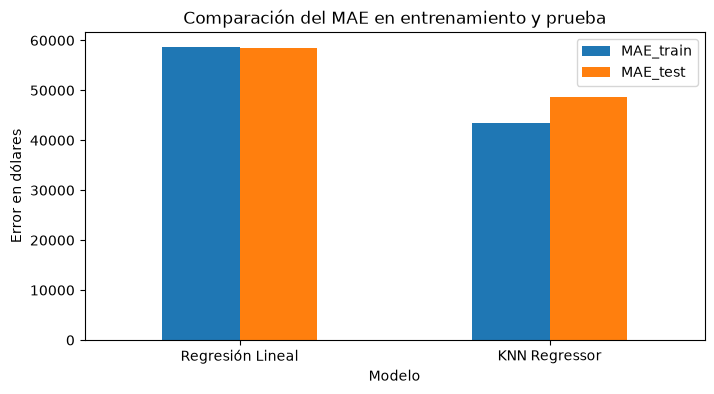

In [9]:
tabla_regresion['Diferencia_MAE'] = abs(
    tabla_regresion['MAE_train'] - tabla_regresion['MAE_test']
)

display(tabla_regresion.round(3))

mejor_regresion = tabla_regresion['MAE_test'].idxmin()
print('El modelo con menor error en prueba es:', mejor_regresion)
print('MAE de prueba: USD', round(tabla_regresion.loc[mejor_regresion, 'MAE_test'], 2))
print('RMSE de prueba: USD', round(tabla_regresion.loc[mejor_regresion, 'RMSE_test'], 2))
print('R2 de prueba:', round(tabla_regresion.loc[mejor_regresion, 'R2_test'], 3))

# Comparamos entrenamiento y prueba para revisar la generalización
print('\nDiagnóstico de los modelos de regresión:')
for nombre in tabla_regresion.index:
    r2_train = tabla_regresion.loc[nombre, 'R2_train']
    r2_test = tabla_regresion.loc[nombre, 'R2_test']
    diferencia = r2_train - r2_test

    print(nombre)
    print('R2 entrenamiento:', round(r2_train, 3))
    print('R2 prueba:', round(r2_test, 3))
    print('Diferencia:', round(diferencia, 3))

    if diferencia > 0.15:
        print('Señal de posible overfitting.')
    elif r2_train < 0.30 and r2_test < 0.30:
        print('Señal de posible underfitting.')
    else:
        print('No se observa una brecha importante entre entrenamiento y prueba.')
    print('---')

tabla_regresion[['MAE_train', 'MAE_test']].plot(kind='bar', figsize=(8,4))
plt.title('Comparación del MAE en entrenamiento y prueba')
plt.ylabel('Error en dólares')
plt.xlabel('Modelo')
plt.xticks(rotation=0)
plt.show()

### Mi explicación de los resultados y el gráfico

**Por qué lo hice así:** No quise elegir al ganador mirando solo una métrica de entrenamiento. Comparé el **MAE en prueba**, la diferencia entre entrenamiento y prueba, y también los valores de **R²** para detectar posibles problemas de generalización.

**Qué muestra la tabla:** KNN obtuvo un MAE de prueba de **USD 48.611,80** frente a **USD 58.400,07** de Regresión Lineal, una mejora aproximada de **USD 9.788,26**. La diferencia absoluta entre MAE de entrenamiento y prueba es de **USD 5.065,14** para KNN y de **USD 331,90** para Regresión Lineal. En R², KNN pasó de **0,767 en entrenamiento a 0,735 en prueba**, una diferencia de **0,032**; no hay una caída tan grande como para afirmar un sobreajuste fuerte solo a partir de esta comparación.

**Qué muestra el gráfico de barras:** Para cada modelo aparecen las barras de MAE de entrenamiento y prueba. Las barras de KNN están más bajas, lo que significa menor error, aunque la de prueba es más alta que la de entrenamiento. Las dos barras de Regresión Lineal son más parecidas entre sí, pero ambas reflejan errores mayores.

**Qué concluyo:** Prefiero KNN en este conjunto porque funciona mejor en prueba. No confundo «menor diferencia entre entrenamiento y prueba» con «mejor modelo»: un modelo puede ser estable y aun así equivocarse más.


### Cross Validation para regresión

Como vimos en clases, la validación cruzada divide los datos de entrenamiento en varias partes. El modelo se entrena y valida varias veces. Revisaremos el promedio y la desviación estándar de los resultados.

Para que la normalización se calcule nuevamente en cada división, utilizamos Pipeline junto con cross_validate.

In [10]:
# Tomamos una muestra del conjunto de entrenamiento para reducir el tiempo de cálculo
N_CV_REG = min(2500, len(X_train_reg_dummies))
X_cv_reg = X_train_reg_dummies.sample(n=N_CV_REG, random_state=RANDOM_STATE)
y_cv_reg = y_train_reg.loc[X_cv_reg.index]

# Creamos los modelos para Cross Validation
modelo_lineal_cv = Pipeline([
    ('escalado', StandardScaler()),
    ('modelo', LinearRegression())
])

modelo_knn_cv = Pipeline([
    ('escalado', StandardScaler()),
    ('modelo', KNeighborsRegressor(n_neighbors=7))
])

# Aplicamos Cross Validation
cv_lineal = cross_validate(
    modelo_lineal_cv, X_cv_reg, y_cv_reg,
    cv=3,
    scoring='r2',
    return_train_score=True
)

cv_knn = cross_validate(
    modelo_knn_cv, X_cv_reg, y_cv_reg,
    cv=3,
    scoring='r2',
    return_train_score=True
)

print('Regresión Lineal - resultados de cada división:')
print('Entrenamiento:', cv_lineal['train_score'])
print('Validación:', cv_lineal['test_score'])
print('Promedio validación:', np.mean(cv_lineal['test_score']))
print('Desviación estándar:', np.std(cv_lineal['test_score']))

print('\nKNN Regressor - resultados de cada división:')
print('Entrenamiento:', cv_knn['train_score'])
print('Validación:', cv_knn['test_score'])
print('Promedio validación:', np.mean(cv_knn['test_score']))
print('Desviación estándar:', np.std(cv_knn['test_score']))

Regresión Lineal - resultados de cada división:
Entrenamiento: [0.69119213 0.64982753 0.65591704]
Validación: [0.35807933 0.62628152 0.61136599]
Promedio validación: 0.5319089482191033
Desviación estándar: 0.12306683902302136

KNN Regressor - resultados de cada división:
Entrenamiento: [0.68022022 0.66470951 0.70069726]
Validación: [0.55696268 0.59559522 0.47199736]
Promedio validación: 0.5415184203233971
Desviación estándar: 0.051626879160357735


### Mi explicación de los resultados

**Por qué lo hice así:** Apliqué **validación cruzada con tres divisiones** a una muestra del entrenamiento para no depender de un único reparto de datos. El `Pipeline` vuelve a ajustar la normalización dentro de cada división, evitando que los datos usados para validar influyan en el escalado.

**Qué muestran los resultados:** En validación, **Regresión Lineal** obtuvo un **R² promedio de 0,532** y una **desviación estándar de 0,123**. **KNN** obtuvo un **R² promedio de 0,542** y una **desviación estándar de 0,052**. El promedio de KNN es solo un poco mayor, pero su variación entre divisiones fue menor. Las puntuaciones individuales de KNN fueron aproximadamente **0,557**, **0,596** y **0,472**; las de Regresión Lineal fueron **0,358**, **0,626** y **0,611**.

**Qué concluyo:** KNN mantiene una ligera ventaja, aunque los resultados también muestran que el rendimiento cambia según las propiedades seleccionadas para validar. No diría que la validación cruzada prueba una superioridad absoluta; la usaría como evidencia complementaria al conjunto de prueba.


### Interpretación de la validación cruzada de regresión

En las tres divisiones de validación, KNN obtuvo un R² promedio de **0,542** y una desviación estándar de **0,052**. La regresión lineal obtuvo un promedio de **0,532** y una desviación estándar de **0,123**. Los promedios son cercanos, pero KNN varió menos entre las divisiones. Esto respalda su elección, aunque la validación cruzada muestra que el rendimiento puede cambiar según los datos usados en cada división.

## 10. Preparación de los datos para clasificación

Ahora predeciremos el tipo de propiedad. La variable property_type ya fue agrupada en cuatro clases: Departamento, Casa, PH y Otros.

Primero convertimos las variables categóricas l2 y l3 mediante One-Hot Encoding. Después normalizamos los atributos numéricos. El escalador se ajusta solo con entrenamiento y se aplica a prueba.

In [11]:
# Separamos las variables categóricas y numéricas
X_train_clf_dummies = pd.get_dummies(
    X_train_clf,
    columns=features_clf_categoricas,
    drop_first=True
)

X_test_clf_dummies = pd.get_dummies(
    X_test_clf,
    columns=features_clf_categoricas,
    drop_first=True
)

# Igualamos las columnas de entrenamiento y prueba
X_test_clf_dummies = X_test_clf_dummies.reindex(
    columns=X_train_clf_dummies.columns,
    fill_value=0
)

print('Dimensión de X_train:', X_train_clf_dummies.shape)
print('Dimensión de X_test:', X_test_clf_dummies.shape)

# Normalizamos los datos
scaler_clf = StandardScaler()

X_train_clf_scaled = scaler_clf.fit_transform(X_train_clf_dummies)
X_test_clf_scaled = scaler_clf.transform(X_test_clf_dummies)

print('Datos de clasificación preparados correctamente.')

Dimensión de X_train: (6400, 95)
Dimensión de X_test: (1600, 95)
Datos de clasificación preparados correctamente.


### Mi explicación de los resultados

**Por qué lo hice así:** Para clasificar el tipo de propiedad convertí las ubicaciones `l2` y `l3` en columnas numéricas con **One-Hot Encoding** y apliqué **StandardScaler** usando solo entrenamiento. No incluí `property_type` como entrada, ya que esa es justamente la respuesta que el clasificador debe aprender a predecir.

**Qué muestra la salida:** El conjunto preparado para clasificación quedó con **95 columnas numéricas**: **(6.400, 95)** en entrenamiento y **(1.600, 95)** en prueba. La cantidad de filas no cambió; aumentó el número de columnas al representar las categorías.

**Qué concluyo:** Ya puedo comparar modelos de clasificación con la misma información de entrada y sin entregarles directamente la respuesta. La preparación hace que el experimento sea reproducible y evita que la evaluación resulte artificialmente favorable por usar información del test.


## 11. Modelos de clasificación

Implementaremos los cuatro algoritmos permitidos que hemos revisado en clases. Se eligen porque permiten comparar distintas formas de separar las categorías:

1. **Regresión Logística:** modelo de referencia que busca separar las clases mediante relaciones lineales entre los atributos.
2. **KNN:** clasifica una publicación según las propiedades más cercanas. La normalización es importante porque utiliza distancias.
3. **SVM:** busca una frontera que separe las clases. Se utiliza kernel RBF para poder representar separaciones no lineales.
4. **Decision Tree:** realiza divisiones mediante reglas sobre las características. Es fácil de interpretar, pero si crece demasiado puede sobreajustarse.

Los cuatro modelos utilizarán exactamente los mismos datos de entrenamiento y prueba, con división estratificada, para que la comparación sea justa.

In [12]:
# 1. Regresión Logística
modelo_logistico = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
modelo_logistico.fit(X_train_clf_scaled, y_train_clf)

# 2. KNN
modelo_knn = KNeighborsClassifier()
modelo_knn.fit(X_train_clf_scaled, y_train_clf)

# 3. SVM con kernel RBF, como en el ejercicio de Iris
modelo_svm = SVC(kernel='rbf', gamma='auto', probability=True, random_state=RANDOM_STATE)
modelo_svm.fit(X_train_clf_scaled, y_train_clf)

# 4. Árbol de Decisión con parámetros trabajados en clases
modelo_arbol = DecisionTreeClassifier(
    criterion='gini',
    max_depth=5,
    min_samples_leaf=3,
    random_state=100
)
modelo_arbol.fit(X_train_clf_scaled, y_train_clf)

print('Los cuatro modelos fueron entrenados correctamente.')

Los cuatro modelos fueron entrenados correctamente.


### Mi explicación de los resultados

**Por qué lo hice así:** Entrené **Regresión Logística, KNN, SVM y Árbol de Decisión**. Quise comparar métodos distintos: una frontera lineal, vecinos cercanos, una separación mediante kernel y reglas sucesivas de decisión. Usé la misma partición de datos para todos.

**Qué muestra la salida:** La ejecución imprimió **«Los cuatro modelos fueron entrenados correctamente»**. Esto significa que ya puedo pedirles predicciones, pero todavía no me dice cuál funciona mejor. No generé un gráfico en esta celda porque aquí solo entrené los modelos.

**Qué concluyo:** Necesito medirlos con las mismas métricas y observar también cuáles tipos de propiedad confunden. El modelo más complejo o más conocido no necesariamente será el que mejor funcione para Properati.


## 12. Evaluación de los modelos de clasificación

Realizaremos predicciones sobre entrenamiento y prueba. Utilizaremos accuracy, precision, recall, F1 y ROC-AUC. También imprimiremos el classification_report de cada modelo, como en los notebooks de clases.

In [13]:
ETIQUETAS = ['Departamento', 'Casa', 'PH', 'Otros']

modelos_clasificacion = {
    'Regresión Logística': modelo_logistico,
    'KNN': modelo_knn,
    'SVM': modelo_svm,
    'Decision Tree': modelo_arbol
}

resultados_clasificacion = []
predicciones_test = {}

for nombre, modelo in modelos_clasificacion.items():
    # Predicciones de entrenamiento y prueba
    pred_train = modelo.predict(X_train_clf_scaled)
    pred_test = modelo.predict(X_test_clf_scaled)
    predicciones_test[nombre] = pred_test

    # Probabilidades para calcular ROC-AUC multiclase
    prob_test = modelo.predict_proba(X_test_clf_scaled)

    resultados_clasificacion.append({
        'Modelo': nombre,
        'Accuracy_train': accuracy_score(y_train_clf, pred_train),
        'Accuracy_test': accuracy_score(y_test_clf, pred_test),
        'F1_macro_train': f1_score(y_train_clf, pred_train, average='macro', zero_division=0),
        'F1_macro': f1_score(y_test_clf, pred_test, average='macro', zero_division=0),
        'Precision_macro': precision_score(y_test_clf, pred_test, average='macro', zero_division=0),
        'Recall_macro': recall_score(y_test_clf, pred_test, average='macro', zero_division=0),
        'F1_weighted': f1_score(y_test_clf, pred_test, average='weighted', zero_division=0),
        'ROC_AUC': roc_auc_score(
            y_test_clf, prob_test,
            labels=modelo.classes_,
            multi_class='ovr',
            average='macro'
        )
    })

tabla_clasificacion = pd.DataFrame(resultados_clasificacion).set_index('Modelo')
tabla_clasificacion['Diferencia_F1'] = (
    tabla_clasificacion['F1_macro_train'] - tabla_clasificacion['F1_macro']
)
display(tabla_clasificacion.round(3))

,Accuracy_train,Accuracy_test,F1_macro_train,F1_macro,Precision_macro,Recall_macro,F1_weighted,ROC_AUC,Diferencia_F1
Modelo,,,,,,,,,
Regresión Logística,0.873,0.869,0.652,0.610,0.723,0.580,0.844,0.896,0.042
KNN,0.883,0.862,0.687,0.630,0.786,0.581,0.841,0.849,0.057
SVM,0.847,0.849,0.526,0.528,0.778,0.508,0.803,0.856,-0.002
Decision Tree,0.868,0.876,0.680,0.683,0.796,0.634,0.862,0.847,-0.003


### Mi explicación de los resultados

**Por qué lo hice así:** Comparé los clasificadores con **accuracy**, **precision**, **recall**, **F1 macro**, **F1 ponderado** y **ROC-AUC**, porque el dataset tiene clases muy desiguales. Me interesó especialmente F1 macro, que considera por igual Departamento, Casa, PH y Otros.

**Qué muestra la tabla:** En prueba, el **Árbol de Decisión** consiguió **accuracy = 0,876**, **F1 macro = 0,683**, **precision macro = 0,796** y **recall macro = 0,634**. KNN logró **F1 macro = 0,630**, Regresión Logística **0,610** y SVM **0,528**. La Regresión Logística obtuvo el **ROC-AUC más alto: 0,896**, mientras que el árbol alcanzó **0,847**.

**Por qué los números no cuentan exactamente la misma historia:** Un accuracy cercano al 88 % puede verse muy bueno, pero hay muchos más departamentos que otras propiedades; acertar con la clase mayoritaria aumenta mucho esa cifra. F1 macro hace más visible el rendimiento de las categorías pequeñas. ROC-AUC mide otra cosa: la capacidad de separar clases a partir de puntuaciones, no los aciertos finales con las etiquetas elegidas.

**Qué concluyo:** El árbol tiene el mejor equilibrio entre las cuatro clases dentro de estos cuatro modelos, según F1 macro. No significa que sea el mejor en cada métrica: la Regresión Logística destaca en ROC-AUC.


### Matriz de confusión y Classification Report

La matriz de confusión permite observar cuántas propiedades fueron clasificadas correctamente y cuáles se confundieron con otra categoría.

Las filas representan la clase real y las columnas la clase predicha. El classification_report muestra precision, recall y F1 para cada clase.

\nModelo: Regresión Logística
              precision    recall  f1-score   support

Departamento       0.89      0.98      0.93      1181
        Casa       0.81      0.87      0.84       226
          PH       0.60      0.18      0.28       158
       Otros       0.59      0.29      0.38        35

    accuracy                           0.87      1600
   macro avg       0.72      0.58      0.61      1600
weighted avg       0.85      0.87      0.84      1600

Matriz de confusión:
[[1154   12   12    3]
 [  19  197    6    4]
 [ 102   27   29    0]
 [  16    8    1   10]]


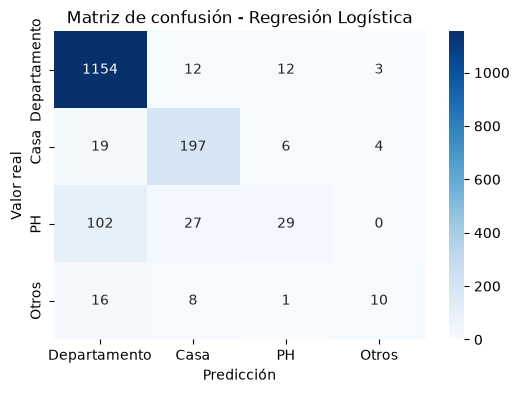

\nModelo: KNN
              precision    recall  f1-score   support

Departamento       0.89      0.97      0.93      1181
        Casa       0.81      0.82      0.82       226
          PH       0.53      0.22      0.31       158
       Otros       0.92      0.31      0.47        35

    accuracy                           0.86      1600
   macro avg       0.79      0.58      0.63      1600
weighted avg       0.84      0.86      0.84      1600

Matriz de confusión:
[[1149   14   18    0]
 [  27  186   12    1]
 [ 104   20   34    0]
 [  14   10    0   11]]


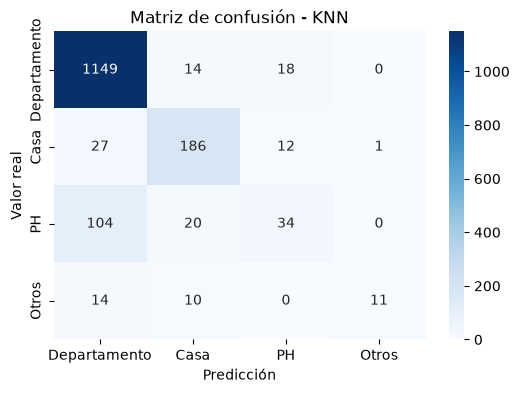

\nModelo: SVM
              precision    recall  f1-score   support

Departamento       0.86      0.98      0.92      1181
        Casa       0.81      0.82      0.82       226
          PH       0.44      0.03      0.05       158
       Otros       1.00      0.20      0.33        35

    accuracy                           0.85      1600
   macro avg       0.78      0.51      0.53      1600
weighted avg       0.81      0.85      0.80      1600

Matriz de confusión:
[[1161   17    3    0]
 [  38  186    2    0]
 [ 137   17    4    0]
 [  18   10    0    7]]


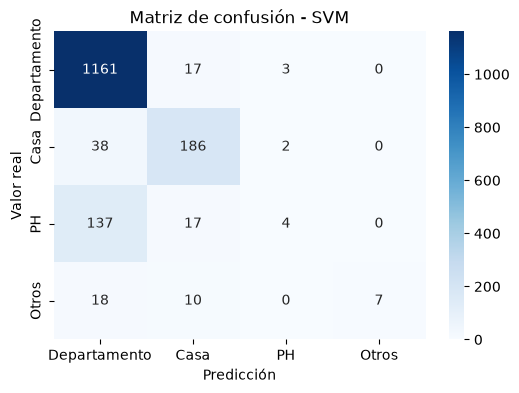

\nModelo: Decision Tree
              precision    recall  f1-score   support

Departamento       0.91      0.97      0.94      1181
        Casa       0.82      0.85      0.84       226
          PH       0.51      0.28      0.37       158
       Otros       0.94      0.43      0.59        35

    accuracy                           0.88      1600
   macro avg       0.80      0.63      0.68      1600
weighted avg       0.86      0.88      0.86      1600

Matriz de confusión:
[[1150    9   22    0]
 [  14  192   19    1]
 [  90   23   45    0]
 [   9    9    2   15]]


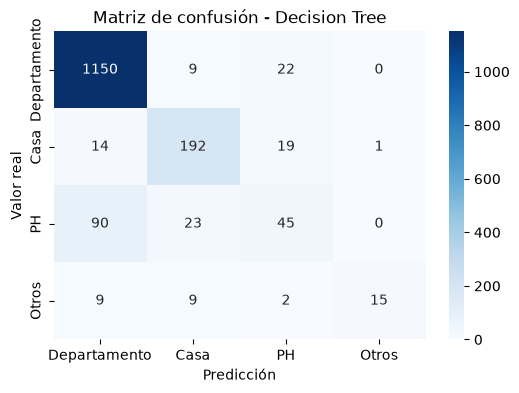

In [14]:
for nombre, modelo in modelos_clasificacion.items():
    print('\\nModelo:', nombre)

    pred_test = predicciones_test[nombre]

    # Reporte de clasificación
    print(classification_report(
        y_test_clf,
        pred_test,
        labels=ETIQUETAS,
        zero_division=0
    ))

    # Matriz de confusión
    matriz = confusion_matrix(y_test_clf, pred_test, labels=ETIQUETAS)
    print('Matriz de confusión:')
    print(matriz)

    plt.figure(figsize=(6, 4))
    sns.heatmap(
        matriz,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=ETIQUETAS,
        yticklabels=ETIQUETAS
    )
    plt.title('Matriz de confusión - ' + nombre)
    plt.xlabel('Predicción')
    plt.ylabel('Valor real')
    plt.show()

### Mi explicación de los resultados y las matrices de confusión

**Por qué lo hice así:** Dibujé una **matriz de confusión para cada clasificador** y mostré su `classification_report`. En cada gráfico, las **filas** representan la categoría real y las **columnas**, la predicción. La diagonal contiene los aciertos; las celdas fuera de ella muestran en qué se equivocó el modelo. Así puedo entender el error, no solo ver un porcentaje general.

**Qué muestran los cuatro gráficos:** El problema más notorio aparece con **PH**. De **158 PH reales**, la **Regresión Logística acertó 29**, **KNN acertó 34**, **SVM acertó solo 4** y el **Árbol de Decisión acertó 45**. En la matriz del árbol, **90 PH fueron confundidos con Departamento** y **23 con Casa**. En cambio, el árbol identificó **1.150 de 1.181 departamentos**, por lo que esa clase domina los aciertos. La categoría Otros tiene apenas **35 casos de prueba** y el árbol identifica correctamente **15**.

**Qué significan precision y recall aquí:** El modelo puede tener buenos resultados globales y aun así omitir muchas publicaciones PH u Otros. Por ejemplo, el árbol obtuvo **recall de PH = 0,28** y **recall de Otros = 0,43**. En la práctica, esas propiedades podrían mostrarse bajo una categoría equivocada y costaría encontrarlas.

**Qué concluyo:** El Árbol de Decisión es el mejor de la comparación principal según F1 macro, pero sus matrices muestran una limitación clara: debería mejorar especialmente en las clases menos frecuentes antes de usarlo para clasificar publicaciones reales.


### Interpretación de las matrices de confusión y cálculo de TP, FP y FN

Las filas de cada matriz representan la clase real y las columnas la clase predicha. En el árbol de decisión, la clase PH es la que más se confunde: de **158 publicaciones PH reales**, **90 se predijeron como Departamento**, **23 como Casa** y **45 se clasificaron correctamente como PH**. Para el negocio, esto significa que una publicación de un PH podría mostrarse en una categoría incorrecta y dificultar que el usuario encuentre el tipo de propiedad que busca.

Para la clase Otros, el árbol identificó correctamente 15 publicaciones (TP), clasificó incorrectamente como Otros 1 publicación de otra clase (FP) y dejó 20 publicaciones Otros clasificadas en otra categoría (FN). Por eso:

- Precision = 15 / (15 + 1) = **0,938**. De las publicaciones que el modelo llamó Otros, el 93,8% realmente era Otros.
- Recall = 15 / (15 + 20) = **0,429**. El modelo encontró el 42,9% de todas las publicaciones que realmente eran Otros.

La precision es alta, pero el recall es bastante menor: cuando el árbol predice Otros suele acertar, aunque todavía deja escapar bastantes publicaciones de esa categoría.

In [15]:
# Utilizamos la matriz de confusión del árbol de decisión
matriz_arbol = confusion_matrix(
    y_test_clf,
    predicciones_test['Decision Tree'],
    labels=ETIQUETAS
)

posicion_otros = ETIQUETAS.index('Otros')

TP = matriz_arbol[posicion_otros, posicion_otros]
FP = matriz_arbol[:, posicion_otros].sum() - TP
FN = matriz_arbol[posicion_otros, :].sum() - TP

precision_otros = TP / (TP + FP) if (TP + FP) > 0 else 0
recall_otros = TP / (TP + FN) if (TP + FN) > 0 else 0

print('TP:', TP)
print('FP:', FP)
print('FN:', FN)
print('Precision de Otros:', round(precision_otros, 3))
print('Recall de Otros:', round(recall_otros, 3))

TP: 15
FP: 1
FN: 20
Precision de Otros: 0.938
Recall de Otros: 0.429


### Mi explicación de los resultados

**Por qué lo hice así:** Quise interpretar la clase **Otros** con ejemplos concretos y no solo con una tabla de porcentajes. Por eso tomé su fila y columna en la matriz del Árbol de Decisión y calculé verdaderos positivos (**TP**), falsos positivos (**FP**) y falsos negativos (**FN**).

**Qué muestra la salida:** Obtuve **TP = 15**, **FP = 1** y **FN = 20**. La **precision = 15 / (15 + 1) = 0,938** significa que, cuando el árbol predijo Otros, acertó alrededor del **93,8 %** de las veces. El **recall = 15 / (15 + 20) = 0,429** significa que solo encontró cerca del **42,9 %** de los Otros que realmente había.

**Qué concluyo:** No basta con fijarme en una precision tan alta. El árbol produce pocas falsas alarmas de Otros, pero deja sin reconocer **20 de los 35** casos reales de esa categoría. Si lo importante fuera no perder esas publicaciones, necesitaría mejorar el recall.


## 13. Balance de clases

En Properati hay muchas más publicaciones de Departamento que de las otras categorías. En la muestra de entrenamiento hay 4.725 Departamento, 902 Casa, 631 PH y 142 Otros. Por esta razón, el accuracy por sí solo puede entregar una impresión equivocada del rendimiento.

Aplicaremos RandomOverSampler solamente sobre los datos de entrenamiento. Los datos de prueba mantendrán su distribución original. Esta técnica aumenta la cantidad de registros de las clases minoritarias mediante la repetición de observaciones.

Distribución antes del balance:
clase
Departamento    4725
Casa             902
PH               631
Otros            142
Name: count, dtype: int64

Distribución después del balance:
clase
Departamento    4725
Casa            4725
PH              4725
Otros           4725
Name: count, dtype: int64



Classification Report - Árbol balanceado
              precision    recall  f1-score   support

Departamento       0.94      0.84      0.89      1181
        Casa       0.77      0.81      0.79       226
          PH       0.31      0.51      0.39       158
       Otros       0.40      0.51      0.45        35

    accuracy                           0.80      1600
   macro avg       0.60      0.67      0.63      1600
weighted avg       0.84      0.80      0.81      1600

Matriz de confusión - Árbol balanceado
[[994  24 147  16]
 [  9 183  24  10]
 [ 51  26  80   1]
 [  8   5   4  18]]


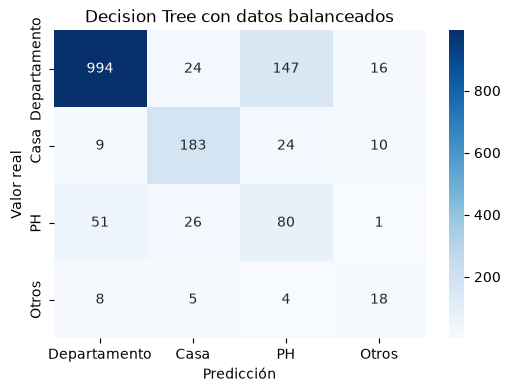

,Sin balance,Con balance
Accuracy,0.876,0.797
Precision macro,0.796,0.605
Recall macro,0.634,0.668
F1 macro,0.683,0.628


Recall de Otros sin balance: 0.429


Recall de Otros con balance: 0.514


In [16]:
# Revisamos la distribución antes del balance
print('Distribución antes del balance:')
print(y_train_clf.value_counts())

# Aplicamos el balance solamente sobre entrenamiento
balanceador = RandomOverSampler(random_state=RANDOM_STATE)
X_train_balanceado, y_train_balanceado = balanceador.fit_resample(
    X_train_clf_scaled,
    y_train_clf
)

print('\nDistribución después del balance:')
print(y_train_balanceado.value_counts())

# Entrenamos nuevamente el árbol de decisión
modelo_arbol_balanceado = DecisionTreeClassifier(
    criterion='gini',
    max_depth=5,
    min_samples_leaf=3,
    random_state=100
)

modelo_arbol_balanceado.fit(X_train_balanceado, y_train_balanceado)

# Evaluamos con el conjunto de prueba original
pred_balanceado = modelo_arbol_balanceado.predict(X_test_clf_scaled)

print('\nClassification Report - Árbol balanceado')
print(classification_report(
    y_test_clf,
    pred_balanceado,
    labels=ETIQUETAS,
    zero_division=0
))

print('Matriz de confusión - Árbol balanceado')
matriz_balanceada = confusion_matrix(
    y_test_clf,
    pred_balanceado,
    labels=ETIQUETAS
)
print(matriz_balanceada)

plt.figure(figsize=(6,4))
sns.heatmap(
    matriz_balanceada,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=ETIQUETAS,
    yticklabels=ETIQUETAS
)
plt.title('Decision Tree con datos balanceados')
plt.xlabel('Predicción')
plt.ylabel('Valor real')
plt.show()

# Comparamos varias métricas antes y después del balance
pred_sin_balance = predicciones_test['Decision Tree']

comparacion_balance = pd.DataFrame({
    'Sin balance': [
        accuracy_score(y_test_clf, pred_sin_balance),
        precision_score(y_test_clf, pred_sin_balance, average='macro', zero_division=0),
        recall_score(y_test_clf, pred_sin_balance, average='macro', zero_division=0),
        f1_score(y_test_clf, pred_sin_balance, average='macro', zero_division=0)
    ],
    'Con balance': [
        accuracy_score(y_test_clf, pred_balanceado),
        precision_score(y_test_clf, pred_balanceado, average='macro', zero_division=0),
        recall_score(y_test_clf, pred_balanceado, average='macro', zero_division=0),
        f1_score(y_test_clf, pred_balanceado, average='macro', zero_division=0)
    ]
}, index=['Accuracy', 'Precision macro', 'Recall macro', 'F1 macro'])

display(comparacion_balance.round(3))

print('Recall de Otros sin balance:', round(recall_score(
    y_test_clf, pred_sin_balance,
    labels=['Otros'], average='macro', zero_division=0
), 3))
print('Recall de Otros con balance:', round(recall_score(
    y_test_clf, pred_balanceado,
    labels=['Otros'], average='macro', zero_division=0
), 3))

### Mi explicación de los resultados y el gráfico

**Por qué lo hice así:** Observé un desbalance importante: en entrenamiento había **4.725 departamentos**, pero solo **142 registros de Otros**. Probé **RandomOverSampler** para repetir observaciones de las clases minoritarias en el entrenamiento. Dejé los datos de prueba sin modificar para evaluar con una distribución realista.

**Qué muestran las tablas:** Después del balance, cada clase tuvo **4.725 registros de entrenamiento**. Al volver a entrenar el árbol, el **recall macro subió de 0,634 a 0,668** y el **recall de Otros pasó de 0,429 a 0,514**. Sin embargo, el **accuracy bajó de 0,876 a 0,797**, la **precision macro de 0,796 a 0,605** y el **F1 macro de 0,683 a 0,628**.

**Qué muestra la nueva matriz de confusión:** El árbol balanceado reconoció **18 de 35 Otros**, frente a **15 antes**, y acertó **80 de 158 PH**, frente a **45 antes**. Pero ahora confundió **147 departamentos con PH**, cuando antes eran **22**. Es decir, encontró más clases minoritarias a costa de equivocarse más con otros tipos de propiedades.

**Qué concluyo:** Balancear no mejora automáticamente todo el modelo. Si el negocio quisiera detectar la mayor cantidad posible de PH y Otros, esta versión podría ser útil. Si busco un mejor equilibrio general entre las cuatro categorías, con estos resultados prefiero el árbol sin balance.


### Interpretación del balance de clases

El balance aumentó el recall de la clase Otros de **0,429 a 0,514**, y el recall macro pasó de **0,634 a 0,668**. Sin embargo, el accuracy bajó de **0,876 a 0,797**, la precision macro de **0,796 a 0,605** y el F1 macro de **0,683 a 0,628**.

Esto muestra el intercambio entre detectar más casos minoritarios y generar más falsas alarmas. Para este trabajo no se reemplaza automáticamente el árbol original por el balanceado: si la prioridad fuera encontrar más publicaciones Otros, el balance puede servir; si se busca el mejor equilibrio general entre las cuatro categorías, el árbol sin balance obtiene mejor F1 macro.

## 14. Cross Validation y diagnóstico de generalización

Como en el notebook de Cross Validation del profesor, utilizaremos cross_validate para obtener varios resultados, el promedio y la desviación estándar. Para reducir el tiempo de cálculo se toma una muestra reproducible de 2.500 registros del conjunto de entrenamiento; la validación cruzada no utiliza el conjunto de prueba.

También compararemos el F1 de entrenamiento y prueba. Un resultado muy alto en entrenamiento y claramente menor en prueba puede indicar overfitting. Un resultado bajo en ambos puede indicar underfitting.

In [17]:
# Usamos una muestra del entrenamiento para reducir el tiempo de cálculo
N_CV_CLF = min(2500, len(X_train_clf_dummies))
X_cv_clf = X_train_clf_dummies.sample(n=N_CV_CLF, random_state=RANDOM_STATE)
y_cv_clf = y_train_clf.loc[X_cv_clf.index]

# Creamos los modelos para la validación cruzada
modelos_cv = {
    'Regresión Logística': Pipeline([
        ('escalado', StandardScaler()),
        ('modelo', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),
    'KNN': Pipeline([
        ('escalado', StandardScaler()),
        ('modelo', KNeighborsClassifier())
    ]),
    'SVM': Pipeline([
        ('escalado', StandardScaler()),
        ('modelo', SVC(kernel='rbf', gamma='auto'))
    ]),
    'Decision Tree': Pipeline([
        ('escalado', StandardScaler()),
        ('modelo', DecisionTreeClassifier(
            criterion='gini', max_depth=5,
            min_samples_leaf=3, random_state=100
        ))
    ])
}

resultados_cv = []

for nombre, modelo in modelos_cv.items():
    cv_resultado = cross_validate(
        modelo,
        X_cv_clf,
        y_cv_clf,
        cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
        scoring='f1_macro',
        return_train_score=True
    )

    resultados_cv.append({
        'Modelo': nombre,
        'F1_train_promedio': np.mean(cv_resultado['train_score']),
        'F1_validacion_promedio': np.mean(cv_resultado['test_score']),
        'Desviacion_estandar': np.std(cv_resultado['test_score'])
    })

tabla_cv = pd.DataFrame(resultados_cv).set_index('Modelo')
display(tabla_cv.round(3))

print('Los resultados muestran el promedio y la desviación estándar de las divisiones.')

,F1_train_promedio,F1_validacion_promedio,Desviacion_estandar
Modelo,,,
Regresión Logística,0.683,0.543,0.022
KNN,0.558,0.437,0.014
SVM,0.454,0.412,0.001
Decision Tree,0.666,0.593,0.032


Los resultados muestran el promedio y la desviación estándar de las divisiones.


### Mi explicación de los resultados

**Por qué lo hice así:** Realicé **validación cruzada estratificada con tres divisiones** en una muestra de entrenamiento. Usé F1 macro para que las clases pequeñas tengan el mismo peso que Departamento al comparar modelos. El `Pipeline` aplica correctamente el escalado dentro de cada división.

**Qué muestra la tabla:** El **Árbol de Decisión** obtuvo el mejor **F1 macro promedio de validación = 0,593**, seguido de **Regresión Logística = 0,543**, **KNN = 0,437** y **SVM = 0,412**. Las desviaciones estándar fueron **0,032**, **0,022**, **0,014** y **0,001**, respectivamente. Un valor de desviación pequeño solo indica que los resultados fueron parecidos entre divisiones, no que el modelo sea bueno: SVM fue bastante estable, pero su F1 promedio fue el más bajo.

**Qué concluyo:** El árbol mantiene la mejor posición entre los cuatro modelos en esta evaluación adicional. Los promedios de validación son inferiores a algunas métricas obtenidas en el test, así que debo reconocer que el resultado puede variar según la muestra usada y evitar prometer el mismo desempeño con cualquier dato nuevo.


### Comparación de overfitting y underfitting en Decision Tree

El parámetro max_depth controla cuántos niveles puede tener el árbol. Compararemos un árbol muy simple (profundidad 1), uno limitado a profundidad 5 y otro sin límite de profundidad.

La comparación permite ver dos problemas: un árbol demasiado simple puede no aprender suficiente información (underfitting); uno demasiado profundo puede memorizar los datos de entrenamiento (overfitting).

In [18]:
# Árbol simple
arbol_simple = DecisionTreeClassifier(max_depth=1, random_state=100)
arbol_simple.fit(X_train_clf_scaled, y_train_clf)

# Árbol utilizado en la comparación principal
arbol_profundidad_5 = DecisionTreeClassifier(
    criterion='gini', max_depth=5,
    min_samples_leaf=3, random_state=100
)
arbol_profundidad_5.fit(X_train_clf_scaled, y_train_clf)

# Árbol sin límite de profundidad
arbol_sin_limite = DecisionTreeClassifier(random_state=100)
arbol_sin_limite.fit(X_train_clf_scaled, y_train_clf)

arboles = {
    'Árbol simple (profundidad 1)': arbol_simple,
    'Árbol profundidad 5': arbol_profundidad_5,
    'Árbol sin límite': arbol_sin_limite
}

resultados_arboles = []

for nombre, modelo in arboles.items():
    pred_train = modelo.predict(X_train_clf_scaled)
    pred_test = modelo.predict(X_test_clf_scaled)

    resultados_arboles.append({
        'Modelo': nombre,
        'F1_train': f1_score(y_train_clf, pred_train, average='macro', zero_division=0),
        'F1_test': f1_score(y_test_clf, pred_test, average='macro', zero_division=0)
    })

tabla_arboles = pd.DataFrame(resultados_arboles).set_index('Modelo')
tabla_arboles['Diferencia'] = tabla_arboles['F1_train'] - tabla_arboles['F1_test']
display(tabla_arboles.round(3))

,F1_train,F1_test,Diferencia
Modelo,,,
Árbol simple (profundidad 1),0.418,0.426,-0.008
Árbol profundidad 5,0.680,0.683,-0.003
Árbol sin límite,0.998,0.691,0.307


### Mi explicación de los resultados

**Por qué lo hice así:** Entrené tres árboles con distinta complejidad para comprobar cómo afecta la profundidad. Uno tiene **profundidad 1**, otro **profundidad 5** y el tercero **no tiene límite**. Comparé su **F1 macro en entrenamiento y prueba**, porque memorizar el entrenamiento no garantiza predecir bien datos nuevos.

**Qué muestra la tabla:** El árbol simple obtuvo **0,418 en entrenamiento** y **0,426 en prueba**, valores bajos que sugieren **underfitting**: no aprendió lo suficiente. El árbol de profundidad 5 consiguió **0,680 y 0,683**, respectivamente, con resultados muy parecidos. El árbol sin límite llegó a **0,998 en entrenamiento**, pero bajó a **0,691 en prueba**, una diferencia de **0,307**, que es una señal clara de **overfitting**.

**Qué concluyo:** Aunque el árbol sin límite consiguió un F1 de prueba ligeramente superior al de profundidad 5 (**0,691 frente a 0,683**) en esta división, la diferencia tan grande respecto del entrenamiento me hace desconfiar de su estabilidad. Mantengo el árbol de profundidad 5 como una elección más conservadora dentro de la comparación principal, sin afirmar que sea el mejor posible para todos los datos.


## 15. Selección del mejor clasificador y análisis de métricas

Para elegir el modelo se prioriza **F1 macro**, porque las cuatro clases no tienen la misma cantidad de publicaciones y no queremos que el resultado dependa principalmente de Departamento.

En esta ejecución, Decision Tree obtuvo el mayor F1 macro en prueba (**0,683**), seguido de KNN (**0,630**), Regresión Logística (**0,610**) y SVM (**0,528**). En validación cruzada, Decision Tree también obtuvo el mayor F1 macro promedio (**0,593**, desviación estándar **0,032**). Su F1 en entrenamiento fue **0,680** y en prueba **0,683**, por lo que no se observa una brecha que indique overfitting en el árbol limitado a profundidad 5.

Regresión Logística obtuvo el mayor ROC-AUC (**0,896**), por lo que también separa bien las clases al considerar sus probabilidades. Sin embargo, Decision Tree presenta el mejor F1 macro y el mejor recall macro (**0,634**) en prueba. Como el objetivo es clasificar las cuatro categorías y no solamente ordenar probabilidades, se selecciona Decision Tree. Si el objetivo principal fuera la calidad de las probabilidades, Regresión Logística sería una alternativa que habría que considerar.

**Ventajas y desventajas de las métricas en este caso:**

- **Accuracy:** es fácil de entender porque indica la proporción total de publicaciones bien clasificadas. Su desventaja es que puede parecer alto aunque el modelo falle en PH y Otros, que son minoritarias.
- **Precision:** muestra cuántas publicaciones predichas como una categoría realmente pertenecen a ella. Una precision baja puede hacer que se muestren propiedades en una categoría equivocada.
- **Recall:** muestra cuántas publicaciones reales de una categoría logra encontrar el modelo. Un recall bajo en PH u Otros significa que varias publicaciones de esos tipos quedan clasificadas como otra cosa.
- **F1:** combina precision y recall. Es útil cuando se necesita equilibrio entre no generar demasiadas falsas alarmas y no dejar demasiados casos sin detectar. No muestra por separado cuál de las dos métricas está causando el problema.
- **ROC-AUC:** evalúa qué tan bien el modelo separa una clase del resto usando probabilidades. Es útil para comparar la capacidad de discriminación, pero no indica por sí sola qué categoría final se asignará ni cuántos errores habrá con un umbral concreto.
- **Promedio macro:** da el mismo peso a Departamento, Casa, PH y Otros. Es apropiado cuando interesa que el modelo funcione también con las clases pequeñas.
- **Promedio weighted:** pondera cada clase por su cantidad de registros. Representa mejor el resultado global de las publicaciones, pero puede ocultar un rendimiento bajo en Otros porque Departamento concentra el 73,82% de los datos.

En este caso, confundir una Casa con un Departamento puede mostrar una publicación en una categoría incorrecta. No detectar un PH o una propiedad Otros puede hacer que esa publicación sea más difícil de encontrar. Por eso se revisan F1 macro y recall macro junto con accuracy y ROC-AUC, en vez de decidir solo por accuracy.

,Accuracy_train,Accuracy_test,F1_macro_train,F1_macro,Precision_macro,Recall_macro,F1_weighted,ROC_AUC,Diferencia_F1,F1_train_promedio,F1_validacion_promedio,Desviacion_estandar,Diferencia_accuracy
Modelo,,,,,,,,,,,,,
Decision Tree,0.868,0.876,0.680,0.683,0.796,0.634,0.862,0.847,-0.003,0.666,0.593,0.032,-0.008
KNN,0.883,0.862,0.687,0.630,0.786,0.581,0.841,0.849,0.057,0.558,0.437,0.014,0.021
Regresión Logística,0.873,0.869,0.652,0.610,0.723,0.580,0.844,0.896,0.042,0.683,0.543,0.022,0.004
SVM,0.847,0.849,0.526,0.528,0.778,0.508,0.803,0.856,-0.002,0.454,0.412,0.001,-0.002


El mejor clasificador según F1 macro en prueba es: Decision Tree
F1 macro entrenamiento: 0.68
F1 macro prueba: 0.683
Diferencia F1 entrenamiento-prueba: -0.003
Recall macro: 0.634
ROC-AUC: 0.847
F1 macro en validación cruzada: 0.593
Desviación estándar: 0.032


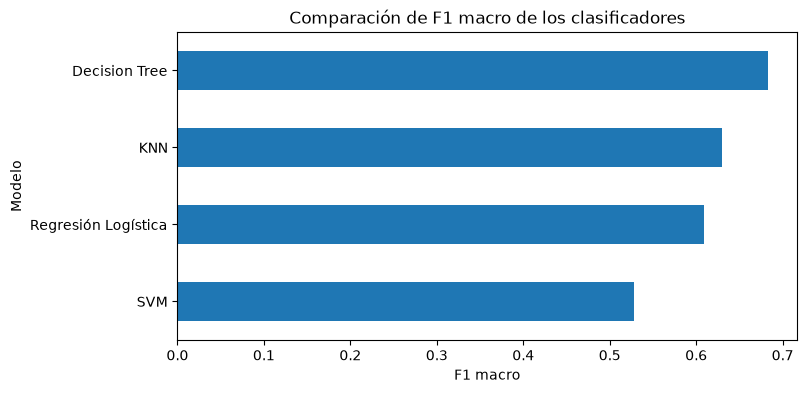

In [19]:
# Agregamos las métricas de validación cruzada a la tabla de clasificación
tabla_final = tabla_clasificacion.join(tabla_cv)

# Comparamos el resultado de entrenamiento con el de prueba
tabla_final['Diferencia_accuracy'] = (
    tabla_final['Accuracy_train'] - tabla_final['Accuracy_test']
)

display(tabla_final.sort_values('F1_macro', ascending=False).round(3))

# Seleccionamos el modelo con mejor F1 macro en prueba
mejor_clasificador = tabla_final['F1_macro'].idxmax()

print('El mejor clasificador según F1 macro en prueba es:', mejor_clasificador)
print('F1 macro entrenamiento:', round(tabla_final.loc[mejor_clasificador, 'F1_macro_train'], 3))
print('F1 macro prueba:', round(tabla_final.loc[mejor_clasificador, 'F1_macro'], 3))
print('Diferencia F1 entrenamiento-prueba:', round(
    tabla_final.loc[mejor_clasificador, 'Diferencia_F1'], 3
))
print('Recall macro:', round(tabla_final.loc[mejor_clasificador, 'Recall_macro'], 3))
print('ROC-AUC:', round(tabla_final.loc[mejor_clasificador, 'ROC_AUC'], 3))
print('F1 macro en validación cruzada:', round(
    tabla_final.loc[mejor_clasificador, 'F1_validacion_promedio'], 3
))
print('Desviación estándar:', round(
    tabla_final.loc[mejor_clasificador, 'Desviacion_estandar'], 3
))

# Mostramos la comparación de F1 macro
tabla_final['F1_macro'].sort_values().plot(kind='barh', figsize=(8,4))
plt.title('Comparación de F1 macro de los clasificadores')
plt.xlabel('F1 macro')
plt.ylabel('Modelo')
plt.show()

### Mi explicación de los resultados y el gráfico

**Por qué lo hice así:** Reuní en una tabla las métricas de prueba, entrenamiento y validación cruzada para tomar una decisión con varias evidencias. Elegí **F1 macro** como criterio principal porque quiero que el modelo considere también PH y Otros, y no solamente los departamentos.

**Qué muestra la tabla final:** Entre los **cuatro clasificadores de la comparación principal**, **Decision Tree** quedó primero con **F1 macro = 0,683**; después aparecen **KNN = 0,630**, **Regresión Logística = 0,610** y **SVM = 0,528**. Para el árbol, el F1 de entrenamiento fue **0,680**, muy cercano al **0,683 de prueba**. Su **recall macro fue 0,634** y en validación cruzada consiguió **F1 promedio = 0,593**.

**Qué muestra el gráfico de barras horizontales:** La barra más larga corresponde a **Decision Tree**, lo que representa el mejor F1 macro de esta comparación. La barra más corta es la de **SVM**, que tuvo el rendimiento más bajo al equilibrar precision y recall de las cuatro clases. El gráfico ayuda a comparar rápidamente modelos, pero no reemplaza las matrices de confusión, donde aparecen errores importantes en PH y Otros.

**Qué concluyo:** Selecciono el Árbol de Decisión de profundidad 5 como el modelo final de la comparación principal. Lo hago por su F1 macro y la poca diferencia entre entrenamiento y prueba, no porque acierte todas las categorías ni porque obtenga el ROC-AUC más alto.


### Conclusiones del trabajo

Para estimar el precio se selecciona KNN Regressor: obtuvo un MAE de prueba de **USD 48.611,80** y R² de **0,735**, mejores que los resultados de la regresión lineal. El error promedio sigue siendo importante para fijar un precio comercial, por lo que la estimación debe tomarse como referencia y no como tasación definitiva.

Para clasificar el tipo de propiedad se selecciona Decision Tree con profundidad 5: obtuvo F1 macro **0,683**, recall macro **0,634** y ROC-AUC **0,847** en prueba. La matriz muestra que todavía confunde especialmente PH con Departamento, así que esa categoría necesita mejorar antes de usar el modelo en un sistema real.

El balanceo permitió encontrar más publicaciones Otros, pero redujo el F1 macro general. La elección depende de si el negocio prefiere detectar más publicaciones minoritarias o mantener un equilibrio general entre las categorías.

Los resultados corresponden a una muestra reproducible del dataset Properati preparado en EV1. Como siguiente paso sería conveniente probar los modelos con publicaciones nuevas, revisar los errores de PH y Otros y ajustar los parámetros sin utilizar el conjunto de prueba para tomar decisiones.

In [20]:
print('CONCLUSIONES BASADAS EN LOS RESULTADOS')

print('\nRegresión:')
print('Modelo seleccionado:', mejor_regresion)
print('MAE en prueba: USD', round(tabla_regresion.loc[mejor_regresion, 'MAE_test'], 2))
print('R2 en prueba:', round(tabla_regresion.loc[mejor_regresion, 'R2_test'], 3))
print('Diferencia de MAE entrenamiento-prueba: USD', round(
    tabla_regresion.loc[mejor_regresion, 'Diferencia_MAE'], 2
))

print('\nClasificación:')
print('Modelo seleccionado:', mejor_clasificador)
print('F1 macro entrenamiento:', round(tabla_final.loc[mejor_clasificador, 'F1_macro_train'], 3))
print('F1 macro prueba:', round(tabla_final.loc[mejor_clasificador, 'F1_macro'], 3))
print('Recall macro en prueba:', round(tabla_final.loc[mejor_clasificador, 'Recall_macro'], 3))
print('ROC-AUC:', round(tabla_final.loc[mejor_clasificador, 'ROC_AUC'], 3))

print('\nBalance de clases:')
display(comparacion_balance.round(3))

print('\nOverfitting y underfitting:')
display(tabla_arboles.round(3))
print('En la tabla anterior se compara el F1 de entrenamiento y prueba para tres profundidades del árbol.')

CONCLUSIONES BASADAS EN LOS RESULTADOS

Regresión:
Modelo seleccionado: KNN Regressor
MAE en prueba: USD 48611.8
R2 en prueba: 0.735
Diferencia de MAE entrenamiento-prueba: USD 5065.14

Clasificación:
Modelo seleccionado: Decision Tree
F1 macro entrenamiento: 0.68
F1 macro prueba: 0.683
Recall macro en prueba: 0.634
ROC-AUC: 0.847

Balance de clases:


,Sin balance,Con balance
Accuracy,0.876,0.797
Precision macro,0.796,0.605
Recall macro,0.634,0.668
F1 macro,0.683,0.628



Overfitting y underfitting:


,F1_train,F1_test,Diferencia
Modelo,,,
Árbol simple (profundidad 1),0.418,0.426,-0.008
Árbol profundidad 5,0.680,0.683,-0.003
Árbol sin límite,0.998,0.691,0.307


En la tabla anterior se compara el F1 de entrenamiento y prueba para tres profundidades del árbol.


### Mi interpretación final de los resultados

**Qué hice:** Volví a reunir en un mismo lugar el modelo de regresión elegido, el clasificador elegido, la comparación del balance de clases y la revisión de profundidad de los árboles. Así puedo relacionar los resultados con las decisiones que tomé durante el trabajo.

**Qué resultados me parecen más importantes:** Para predecir precios elegí **KNN Regressor**, con **MAE de prueba = USD 48.611,80** y **R² = 0,735**. Para reconocer tipos de propiedad seleccioné **Decision Tree (profundidad 5)**, con **F1 macro = 0,683** y **recall macro = 0,634** en prueba. Al balancear clases subió el recall macro (**0,634 a 0,668**), pero bajó el F1 macro (**0,683 a 0,628**). También comprobé que un árbol sin límite puede tener un resultado casi perfecto en entrenamiento (**0,998**) y uno bastante menor en prueba (**0,691**).

**Qué concluyo:** Aprendí que debo justificar la selección de un modelo según el problema que quiero resolver. En regresión me importa cuánto dinero se equivoca; en clasificación, cuánto acierta y a qué categorías deja fuera. Los gráficos, las tablas y las matrices permiten encontrar problemas que una sola métrica no muestra. Estos modelos son una primera aproximación y deberían validarse con nuevas publicaciones antes de usarlos en un sistema real.


## Checklist de la evaluación

| Indicador | Evidencia en el notebook |
|---|---|
| IE 1 | Target continuo price, tipo, valores únicos y distribución |
| IE 2 | Regresión lineal múltiple y KNN Regressor |
| IE 3 | MAE, RMSE y R² en entrenamiento y prueba, en USD |
| IE 4 | Tabla y justificación numérica de la selección del regresor |
| IE 5 | Diferencias entre regresión y clasificación, targets, algoritmos y métricas |
| IE 6 | Correlación Pearson, Spearman, heatmaps y comparación por clase |
| IE 7 | Agrupación de clases, One-Hot Encoding y escalado ajustado en entrenamiento |
| IE 8 | Justificación de variables usadas y descartadas, evitando data leakage |
| IE 9 | Cuatro clasificadores permitidos, misma división estratificada y justificación |
| IE 10 | Comparación train/test, validación cruzada, overfitting y underfitting |
| IE 11 | Classification Report por modelo, métricas macro/weighted y ROC-AUC OVR |
| IE 12 | Matriz de confusión de cada modelo e interpretación de TP, FP y FN |
| IE 13 | RandomOverSampler solo en entrenamiento y comparación con/sin balance |
| IE 14 | Comparación de métricas, validación cruzada y selección del clasificador |
| IE 15 | Ventajas y desventajas de las métricas relacionadas con Properati |

El notebook debe ejecutarse desde la primera celda hasta la última. Antes de entregar, los integrantes deben revisar las conclusiones y poder explicar con sus propias palabras las decisiones y resultados.